El script debe dar tratamiento conjuntos de datos grandes

  1.​ Tomar muestras de 5.000 y 10.000 registros.

  2.​ Calcular la matriz de distancias Gower para cada muestra.

  3.​ Medir tiempo de ejecución y uso de memoria.
  
  4.​ Comparar estabilidad de clusters en muestras de distinto tamaño.​

Muestra de 5000 registros:

In [2]:
import sys
sys.path.append('..')
from utils import cargar_dataset_adult
import pandas as pd
import numpy as np
import time # Para medir el tiempo de ejecución
import psutil # Para medir el uso de memoria
import os # Para obtener el ID del proceso actual

# Configuración para mejor visualización en Jupyter
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

# =================================================================
# Carga del DataFrame desde archivos locales
# =================================================================
df = cargar_dataset_adult()

# =================================================================
# Implementación Vectorizada de Gower para una MUESTRA
# =================================================================

# 1. Preparación de los datos para Gower
# -----------------------------------------------------------------
# Define el tamaño de la muestra
sample_size = 5000

# Tomamos una muestra aleatoria del DataFrame
df_sample = df.sample(n=sample_size, random_state=42).copy()

print(f"--- Se ha tomado una muestra aleatoria de {sample_size} filas. ---")

# Identificar tipos de variables de forma definitiva
# Nota: fnlwgt (final weight) NO se incluye porque es un peso de muestreo del censo,
# no una característica descriptiva. No tiene sentido en el cálculo de similitud.
numeric_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'education-num']
ordinal_cols = ['education']
categorical_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']

# --- Manejo de la Variable Ordinal 'education' ---
education_map = {
    'Preschool': 1, '1st-4th': 2, '5th-6th': 3, '7th-8th': 4, '9th': 5,
    '10th': 6, '11th': 7, '12th': 8, 'HS-grad': 9, 'Some-college': 10,
    'Assoc-voc': 11, 'Assoc-acdm': 12, 'Bachelors': 13, 'Masters': 14,
    'Prof-school': 15, 'Doctorate': 16
}
df['education_rank'] = df['education'].map(education_map)
min_rank = df['education_rank'].min()
max_rank = df['education_rank'].max()
ordinal_rank_range = max_rank - min_rank
df_sample['education'] = (df_sample['education'].map(education_map) - min_rank) / ordinal_rank_range

# Pre-calcular los rangos para las variables numéricas
ranges = {col: df[col].max() - df[col].min() for col in numeric_cols}


# 2. Cálculo Vectorizado de la Matriz de Distancias
# -----------------------------------------------------------------
print("\nCalculando la matriz de distancias (VERSIÓN VECTORIZADA)...")

# --- INICIO DE MEDICIÓN DE RECURSOS ---
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 * 1024) # Memoria en MB
start_time = time.time()
print(f"Uso de memoria antes del cálculo: {mem_before:.2f} MB")
# ------------------------------------


# Paso A: Separar los datos en arrays de NumPy por tipo
df_num = df_sample[numeric_cols].to_numpy(dtype=np.float64)
df_cat = df_sample[categorical_cols].to_numpy(dtype=object)
df_ord = df_sample[ordinal_cols].to_numpy(dtype=np.float64)

# Paso B: Calcular la disimilitud para cada tipo de variable
numeric_dissim = np.sum([
    np.abs(np.subtract.outer(df_num[:, i], df_num[:, i])) / ranges[col]
    for i, col in enumerate(numeric_cols) if ranges[col] > 0
], axis=0)

categorical_dissim = np.sum([
    np.not_equal.outer(df_cat[:, i], df_cat[:, i]).astype(np.float64)
    for i in range(df_cat.shape[1])
], axis=0)

ordinal_dissim = np.sum([
    np.abs(np.subtract.outer(df_ord[:, i], df_ord[:, i]))
    for i in range(df_ord.shape[1])
], axis=0)

# Paso C: Sumar todas las disimilitudes (numerador de Gower)
total_dissimilarity = numeric_dissim + categorical_dissim + ordinal_dissim

# Paso D: Calcular los pesos (denominador de Gower) de forma vectorizada
is_not_nan = ~df_sample.drop(columns=['education_rank'], errors='ignore').isna()
weight_sum = np.dot(is_not_nan.astype(int), is_not_nan.astype(int).T)

# Paso E: Calcular la matriz de Gower final, evitando la división por cero
with np.errstate(divide='ignore', invalid='ignore'):
    gower_matrix_vectorized = np.where(weight_sum > 0, total_dissimilarity / weight_sum, 0)


# --- FIN DE MEDICIÓN DE RECURSOS ---
end_time = time.time()
mem_after = process.memory_info().rss / (1024 * 1024) # Memoria en MB

print("\n--- Resumen de Ejecución (Vectorizado) ---")
print(f"¡Cálculo completado en {end_time - start_time:.4f} segundos!")
print(f"Uso de memoria final: {mem_after:.2f} MB")
print(f"Memoria adicional utilizada por el cálculo: {mem_after - mem_before:.2f} MB")
# ---------------------------------


# 3. Visualización de Resultados
# -----------------------------------------------------------------
gower_matrix_df = pd.DataFrame(gower_matrix_vectorized, index=df_sample.index, columns=df_sample.index)
print("\n--- Matriz de Distancias de Gower resultante ---")
print("(Mostrando las primeras 10x10 para visualización)")

# Retornar el DataFrame lo mostrará en formato tabla
gower_matrix_df.iloc[:10, :10]

--- Se ha tomado una muestra aleatoria de 5000 filas. ---

Calculando la matriz de distancias (VERSIÓN VECTORIZADA)...
Uso de memoria antes del cálculo: 129.34 MB

--- Resumen de Ejecución (Vectorizado) ---
¡Cálculo completado en 4.8878 segundos!
Uso de memoria final: 1298.58 MB
Memoria adicional utilizada por el cálculo: 1169.25 MB

--- Matriz de Distancias de Gower resultante ---
(Mostrando las primeras 10x10 para visualización)


,7762,23881,30507,28911,19484,43031,28188,12761,40834,27875
7762,0.0000,0.2098,0.2867,0.2175,0.3176,0.3295,0.2319,0.3008,0.2662,0.3123
23881,0.2098,0.0000,0.3631,0.0273,0.3941,0.4060,0.3083,0.3595,0.2760,0.3221
30507,0.2867,0.3631,0.0000,0.3536,0.3643,0.3095,0.3452,0.4214,0.4462,0.3657
28911,0.2175,0.0273,0.3536,0.0000,0.3846,0.3787,0.2988,0.3677,0.2487,0.3125
19484,0.3176,0.3941,0.3643,0.3846,0.0000,0.3926,0.3524,0.3857,0.4443,0.4232
43031,0.3295,0.4060,0.3095,0.3787,0.3926,0.0000,0.1068,0.1976,0.3545,0.2607
28188,0.2319,0.3083,0.3452,0.2988,0.3524,0.1068,0.0000,0.1000,0.3010,0.2872
12761,0.3008,0.3595,0.4214,0.3677,0.3857,0.1976,0.1000,0.0000,0.4010,0.3872
40834,0.2662,0.2760,0.4462,0.2487,0.4443,0.3545,0.3010,0.4010,0.0000,0.3092
27875,0.3123,0.3221,0.3657,0.3125,0.4232,0.2607,0.2872,0.3872,0.3092,0.0000


Muestra de 10.000 registros:

In [3]:
import sys
sys.path.append('..')
from utils import cargar_dataset_adult
import pandas as pd
import numpy as np
import time # Para medir el tiempo de ejecución
import psutil # Para medir el uso de memoria
import os # Para obtener el ID del proceso actual

# Configuración para mejor visualización en Jupyter
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

# =================================================================
# Carga del DataFrame desde archivos locales
# =================================================================
df = cargar_dataset_adult()

# =================================================================
# Implementación Vectorizada de Gower para una MUESTRA
# =================================================================

# 1. Preparación de los datos para Gower
# -----------------------------------------------------------------
# Define el tamaño de la muestra
sample_size = 10000

# Tomamos una muestra aleatoria del DataFrame
df_sample = df.sample(n=sample_size, random_state=42).copy()

print(f"--- Se ha tomado una muestra aleatoria de {sample_size} filas. ---")

# Identificar tipos de variables de forma definitiva
# Nota: fnlwgt (final weight) NO se incluye porque es un peso de muestreo del censo,
# no una característica descriptiva. No tiene sentido en el cálculo de similitud.
numeric_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'education-num']
ordinal_cols = ['education']
categorical_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']

# --- Manejo de la Variable Ordinal 'education' ---
education_map = {
    'Preschool': 1, '1st-4th': 2, '5th-6th': 3, '7th-8th': 4, '9th': 5,
    '10th': 6, '11th': 7, '12th': 8, 'HS-grad': 9, 'Some-college': 10,
    'Assoc-voc': 11, 'Assoc-acdm': 12, 'Bachelors': 13, 'Masters': 14,
    'Prof-school': 15, 'Doctorate': 16
}
df['education_rank'] = df['education'].map(education_map)
min_rank = df['education_rank'].min()
max_rank = df['education_rank'].max()
ordinal_rank_range = max_rank - min_rank
df_sample['education'] = (df_sample['education'].map(education_map) - min_rank) / ordinal_rank_range

# Pre-calcular los rangos para las variables numéricas
ranges = {col: df[col].max() - df[col].min() for col in numeric_cols}


# 2. Cálculo Vectorizado de la Matriz de Distancias
# -----------------------------------------------------------------
print("\nCalculando la matriz de distancias (VERSIÓN VECTORIZADA)...")

# --- INICIO DE MEDICIÓN DE RECURSOS ---
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 * 1024) # Memoria en MB
start_time = time.time()
print(f"Uso de memoria antes del cálculo: {mem_before:.2f} MB")
# ------------------------------------


# Paso A: Separar los datos en arrays de NumPy por tipo
df_num = df_sample[numeric_cols].to_numpy(dtype=np.float64)
df_cat = df_sample[categorical_cols].to_numpy(dtype=object)
df_ord = df_sample[ordinal_cols].to_numpy(dtype=np.float64)

# Paso B: Calcular la disimilitud para cada tipo de variable
numeric_dissim = np.sum([
    np.abs(np.subtract.outer(df_num[:, i], df_num[:, i])) / ranges[col]
    for i, col in enumerate(numeric_cols) if ranges[col] > 0
], axis=0)

categorical_dissim = np.sum([
    np.not_equal.outer(df_cat[:, i], df_cat[:, i]).astype(np.float64)
    for i in range(df_cat.shape[1])
], axis=0)

ordinal_dissim = np.sum([
    np.abs(np.subtract.outer(df_ord[:, i], df_ord[:, i]))
    for i in range(df_ord.shape[1])
], axis=0)

# Paso C: Sumar todas las disimilitudes (numerador de Gower)
total_dissimilarity = numeric_dissim + categorical_dissim + ordinal_dissim

# Paso D: Calcular los pesos (denominador de Gower) de forma vectorizada
is_not_nan = ~df_sample.drop(columns=['education_rank'], errors='ignore').isna()
weight_sum = np.dot(is_not_nan.astype(int), is_not_nan.astype(int).T)

# Paso E: Calcular la matriz de Gower final, evitando la división por cero
with np.errstate(divide='ignore', invalid='ignore'):
    gower_matrix_vectorized = np.where(weight_sum > 0, total_dissimilarity / weight_sum, 0)


# --- FIN DE MEDICIÓN DE RECURSOS ---
end_time = time.time()
mem_after = process.memory_info().rss / (1024 * 1024) # Memoria en MB

print("\n--- Resumen de Ejecución (Vectorizado) ---")
print(f"¡Cálculo completado en {end_time - start_time:.4f} segundos!")
print(f"Uso de memoria final: {mem_after:.2f} MB")
print(f"Memoria adicional utilizada por el cálculo: {mem_after - mem_before:.2f} MB")
# ---------------------------------


# 3. Visualización de Resultados
# -----------------------------------------------------------------
gower_matrix_df = pd.DataFrame(gower_matrix_vectorized, index=df_sample.index, columns=df_sample.index)
print("\n--- Matriz de Distancias de Gower resultante ---")
print("(Mostrando las primeras 10x10 para visualización)")

# Retornar el DataFrame lo mostrará en formato tabla
gower_matrix_df.iloc[:10, :10]

--- Se ha tomado una muestra aleatoria de 10000 filas. ---

Calculando la matriz de distancias (VERSIÓN VECTORIZADA)...
Uso de memoria antes del cálculo: 1303.55 MB

--- Resumen de Ejecución (Vectorizado) ---
¡Cálculo completado en 19.2242 segundos!
Uso de memoria final: 4927.66 MB
Memoria adicional utilizada por el cálculo: 3624.11 MB

--- Matriz de Distancias de Gower resultante ---
(Mostrando las primeras 10x10 para visualización)


,7762,23881,30507,28911,19484,43031,28188,12761,40834,27875
7762,0.0000,0.2098,0.2867,0.2175,0.3176,0.3295,0.2319,0.3008,0.2662,0.3123
23881,0.2098,0.0000,0.3631,0.0273,0.3941,0.4060,0.3083,0.3595,0.2760,0.3221
30507,0.2867,0.3631,0.0000,0.3536,0.3643,0.3095,0.3452,0.4214,0.4462,0.3657
28911,0.2175,0.0273,0.3536,0.0000,0.3846,0.3787,0.2988,0.3677,0.2487,0.3125
19484,0.3176,0.3941,0.3643,0.3846,0.0000,0.3926,0.3524,0.3857,0.4443,0.4232
43031,0.3295,0.4060,0.3095,0.3787,0.3926,0.0000,0.1068,0.1976,0.3545,0.2607
28188,0.2319,0.3083,0.3452,0.2988,0.3524,0.1068,0.0000,0.1000,0.3010,0.2872
12761,0.3008,0.3595,0.4214,0.3677,0.3857,0.1976,0.1000,0.0000,0.4010,0.3872
40834,0.2662,0.2760,0.4462,0.2487,0.4443,0.3545,0.3010,0.4010,0.0000,0.3092
27875,0.3123,0.3221,0.3657,0.3125,0.4232,0.2607,0.2872,0.3872,0.3092,0.0000


## Paso 4: Comparación de Estabilidad de Clusters

Ahora vamos a comparar la estabilidad de los clusters entre las muestras de 5,000 y 10,000 registros usando AgglomerativeClustering con las matrices de Gower calculadas.


In [4]:
import sys
sys.path.append('..')
from utils import cargar_dataset_adult
import pandas as pd
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Función para calcular matriz de Gower
def calcular_matriz_gower(df_sample):
    """Calcula la matriz de distancias de Gower para una muestra"""
    
    # Variables
    numeric_cols = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week', 'education-num']
    ordinal_cols = ['education']
    categorical_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 
                       'race', 'sex', 'native-country', 'income']
    
    # Mapa ordinal
    education_map = {
        'Preschool': 1, '1st-4th': 2, '5th-6th': 3, '7th-8th': 4, '9th': 5,
        '10th': 6, '11th': 7, '12th': 8, 'HS-grad': 9, 'Some-college': 10,
        'Assoc-voc': 11, 'Assoc-acdm': 12, 'Bachelors': 13, 'Masters': 14,
        'Prof-school': 15, 'Doctorate': 16
    }
    
    # Normalizar education
    df_sample = df_sample.copy()
    df['education_rank'] = df['education'].map(education_map)
    min_rank = df['education_rank'].min()
    max_rank = df['education_rank'].max()
    ordinal_rank_range = max_rank - min_rank
    df_sample['education'] = (df_sample['education'].map(education_map) - min_rank) / ordinal_rank_range
    
    # Rangos numéricos
    ranges = {col: df[col].max() - df[col].min() for col in numeric_cols}
    
    # Convertir a arrays
    df_num = df_sample[numeric_cols].to_numpy(dtype=np.float64)
    df_cat = df_sample[categorical_cols].to_numpy(dtype=object)
    df_ord = df_sample[ordinal_cols].to_numpy(dtype=np.float64)
    
    # Calcular disimilitudes
    numeric_dissim = np.sum([
        np.abs(np.subtract.outer(df_num[:, i], df_num[:, i])) / ranges[col]
        for i, col in enumerate(numeric_cols) if ranges[col] > 0
    ], axis=0)
    
    categorical_dissim = np.sum([
        np.not_equal.outer(df_cat[:, i], df_cat[:, i]).astype(np.float64)
        for i in range(df_cat.shape[1])
    ], axis=0)
    
    ordinal_dissim = np.sum([
        np.abs(np.subtract.outer(df_ord[:, i], df_ord[:, i]))
        for i in range(df_ord.shape[1])
    ], axis=0)
    
    total_dissimilarity = numeric_dissim + categorical_dissim + ordinal_dissim
    
    # Pesos
    is_not_nan = ~df_sample.drop(columns=['education_rank'], errors='ignore').isna()
    weight_sum = np.dot(is_not_nan.astype(int), is_not_nan.astype(int).T)
    
    # Matriz final
    with np.errstate(divide='ignore', invalid='ignore'):
        gower_matrix = np.where(weight_sum > 0, total_dissimilarity / weight_sum, 0)
    
    return gower_matrix

print("Preparando datos para comparación...")


Preparando datos para comparación...


In [5]:
# Cargar dataset completo
df = cargar_dataset_adult()

# Crear muestras con la misma semilla para comparación justa
np.random.seed(42)
sample_5k = df.sample(n=5000, random_state=42)
sample_10k = df.sample(n=10000, random_state=42)

print(f"Muestra 5K: {len(sample_5k)} registros")
print(f"Muestra 10K: {len(sample_10k)} registros")

# Calcular matrices de Gower
print("\nCalculando matriz de Gower para muestra de 5,000...")
gower_5k = calcular_matriz_gower(sample_5k)

print("Calculando matriz de Gower para muestra de 10,000...")
gower_10k = calcular_matriz_gower(sample_10k)

print("\nMatrices calculadas correctamente.")


Muestra 5K: 5000 registros
Muestra 10K: 10000 registros

Calculando matriz de Gower para muestra de 5,000...
Calculando matriz de Gower para muestra de 10,000...

Matrices calculadas correctamente.


In [6]:
# Aplicar AgglomerativeClustering con diferentes valores de k
k_values = [3, 4, 5, 6]

# Asegurar que la diagonal de las matrices sea cero (requerido para silhouette_score)
np.fill_diagonal(gower_5k, 0)
np.fill_diagonal(gower_10k, 0)

results_5k = {}
results_10k = {}

print("Aplicando clustering a muestra de 5,000 registros...")
for k in k_values:
    agg = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = agg.fit_predict(gower_5k)
    silhouette = silhouette_score(gower_5k, labels, metric='precomputed')
    results_5k[k] = {'labels': labels, 'silhouette': silhouette}
    print(f"  k={k}: Silhouette = {silhouette:.4f}")

print("\nAplicando clustering a muestra de 10,000 registros...")
for k in k_values:
    agg = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = agg.fit_predict(gower_10k)
    silhouette = silhouette_score(gower_10k, labels, metric='precomputed')
    results_10k[k] = {'labels': labels, 'silhouette': silhouette}
    print(f"  k={k}: Silhouette = {silhouette:.4f}")

print("\nClustering completado para ambas muestras.")


Aplicando clustering a muestra de 5,000 registros...
  k=3: Silhouette = 0.3572
  k=4: Silhouette = 0.3213
  k=5: Silhouette = 0.2994
  k=6: Silhouette = 0.2810

Aplicando clustering a muestra de 10,000 registros...
  k=3: Silhouette = 0.3489
  k=4: Silhouette = 0.3360
  k=5: Silhouette = 0.2895
  k=6: Silhouette = 0.2218

Clustering completado para ambas muestras.


In [7]:
# ============================================================================
# ANÁLISIS DE ESTABILIDAD: Comparación entre muestras de 5K y 10K
# ============================================================================
# 
# CONCEPTO: La estabilidad mide si el clustering produce resultados similares
# con diferentes tamaños de muestra. Alta estabilidad = patrones reales y robustos.
# 
# CRITERIOS:
# 1. ¿Ambas muestras sugieren el mismo k óptimo?
# 2. ¿Los valores de Silhouette son similares para cada k?
# ============================================================================

print("="*70)
print("ANÁLISIS DE ESTABILIDAD DE CLUSTERS")
print("="*70)

# Crear tabla comparativa
comparison_df = pd.DataFrame({
    'k': k_values,
    'Silhouette 5K': [results_5k[k]['silhouette'] for k in k_values],
    'Silhouette 10K': [results_10k[k]['silhouette'] for k in k_values],
    'Diferencia': [abs(results_5k[k]['silhouette'] - results_10k[k]['silhouette']) for k in k_values]
})

print("\nTabla Comparativa:")
print(comparison_df.to_string(index=False))

# Determinar k óptimo para cada muestra
best_k_5k = max(k_values, key=lambda k: results_5k[k]['silhouette'])
best_k_10k = max(k_values, key=lambda k: results_10k[k]['silhouette'])

# Diferencia promedio
mean_diff = comparison_df['Diferencia'].mean()

print(f"\n{'='*70}")
print("CONCLUSIONES DE ESTABILIDAD:")
print(f"{'='*70}")

# Criterio 1: ¿Mismo k óptimo?
print(f"\n1. K óptimo:")
print(f"   • Muestra 5K:  k = {best_k_5k} (Silhouette = {results_5k[best_k_5k]['silhouette']:.4f})")
print(f"   • Muestra 10K: k = {best_k_10k} (Silhouette = {results_10k[best_k_10k]['silhouette']:.4f})")

if best_k_5k == best_k_10k:
    print(f"   ✓ CONSISTENTE: Ambas muestras sugieren k = {best_k_5k}")
else:
    print(f"   ✗ INCONSISTENTE: Sugieren valores diferentes de k")

# Criterio 2: ¿Silhouette similares?
print(f"\n2. Diferencia promedio en Silhouette: {mean_diff:.4f}")

if mean_diff < 0.05:
    estabilidad = "ALTA"
    interpretacion = "Los clusters son muy estables y representan patrones robustos"
elif mean_diff < 0.10:
    estabilidad = "MODERADA"
    interpretacion = "Los clusters son relativamente estables con variación menor"
else:
    estabilidad = "BAJA"
    interpretacion = "Los clusters muestran variación significativa con el tamaño de muestra"

print(f"   → Estabilidad: {estabilidad}")
print(f"   → {interpretacion}")

print(f"\n{'='*70}\n")


ANÁLISIS DE ESTABILIDAD DE CLUSTERS

Tabla Comparativa:
 k  Silhouette 5K  Silhouette 10K  Diferencia
 3         0.3572          0.3489      0.0083
 4         0.3213          0.3360      0.0147
 5         0.2994          0.2895      0.0099
 6         0.2810          0.2218      0.0591

CONCLUSIONES DE ESTABILIDAD:

1. K óptimo:
   • Muestra 5K:  k = 3 (Silhouette = 0.3572)
   • Muestra 10K: k = 3 (Silhouette = 0.3489)
   ✓ CONSISTENTE: Ambas muestras sugieren k = 3

2. Diferencia promedio en Silhouette: 0.0230
   → Estabilidad: ALTA
   → Los clusters son muy estables y representan patrones robustos




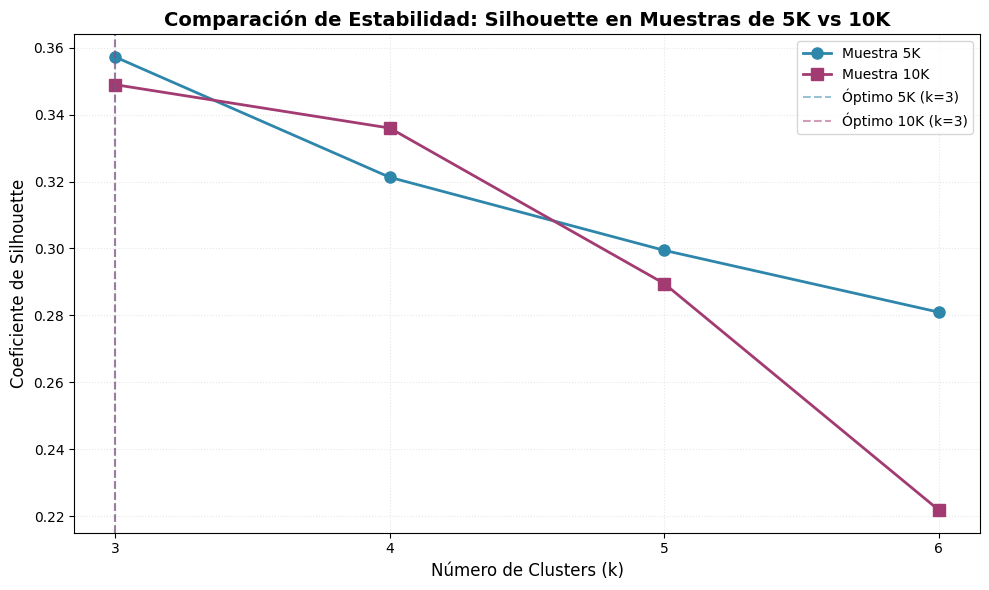

✓ Gráfico de estabilidad generado


In [8]:
# Visualización gráfica de estabilidad (opcional)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

k_array = np.array(k_values)
sil_5k = np.array([results_5k[k]['silhouette'] for k in k_values])
sil_10k = np.array([results_10k[k]['silhouette'] for k in k_values])

ax.plot(k_array, sil_5k, marker='o', linewidth=2, markersize=8, label='Muestra 5K', color='#2E86AB')
ax.plot(k_array, sil_10k, marker='s', linewidth=2, markersize=8, label='Muestra 10K', color='#A23B72')

# Marcar los k óptimos
ax.axvline(x=best_k_5k, color='#2E86AB', linestyle='--', alpha=0.5, label=f'Óptimo 5K (k={best_k_5k})')
ax.axvline(x=best_k_10k, color='#A23B72', linestyle='--', alpha=0.5, label=f'Óptimo 10K (k={best_k_10k})')

ax.set_xlabel('Número de Clusters (k)', fontsize=12)
ax.set_ylabel('Coeficiente de Silhouette', fontsize=12)
ax.set_title('Comparación de Estabilidad: Silhouette en Muestras de 5K vs 10K', fontsize=14, fontweight='bold')
ax.set_xticks(k_values)
ax.grid(True, alpha=0.3, linestyle=':')
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()


